# Between Speaker Agreement in WCS Data

COG 260: Data, Computation, and The Mind (Yang Xu)

Data source: https://linguistics.berkeley.edu/wcs/data.html

______________________________________________

Import helper function file for WCS data analysis.

In [16]:
from wcs_helper_functions import *

Import relevant Python libraries.

In [17]:
import numpy as np
import scipy
import pandas as pd
from scipy import spatial
from random import random
%matplotlib inline

In [18]:
munsellInfo = readChipData('./WCS_data_core/chip.txt');
indexCoord = munsellInfo[1]
coordIndex = munsellInfo[0]

In [19]:
cielabCoord = readClabData('./WCS_data_core/cnum-vhcm-lab-new.txt')

In [20]:
namingData = readNamingData('./WCS_data_core/term.txt')

In [21]:
fociData = readFociData('./WCS_data_core/foci-exp.txt');

In [22]:
speakerInfo = readSpeakerData('./WCS_data_core/spkr-lsas.txt')

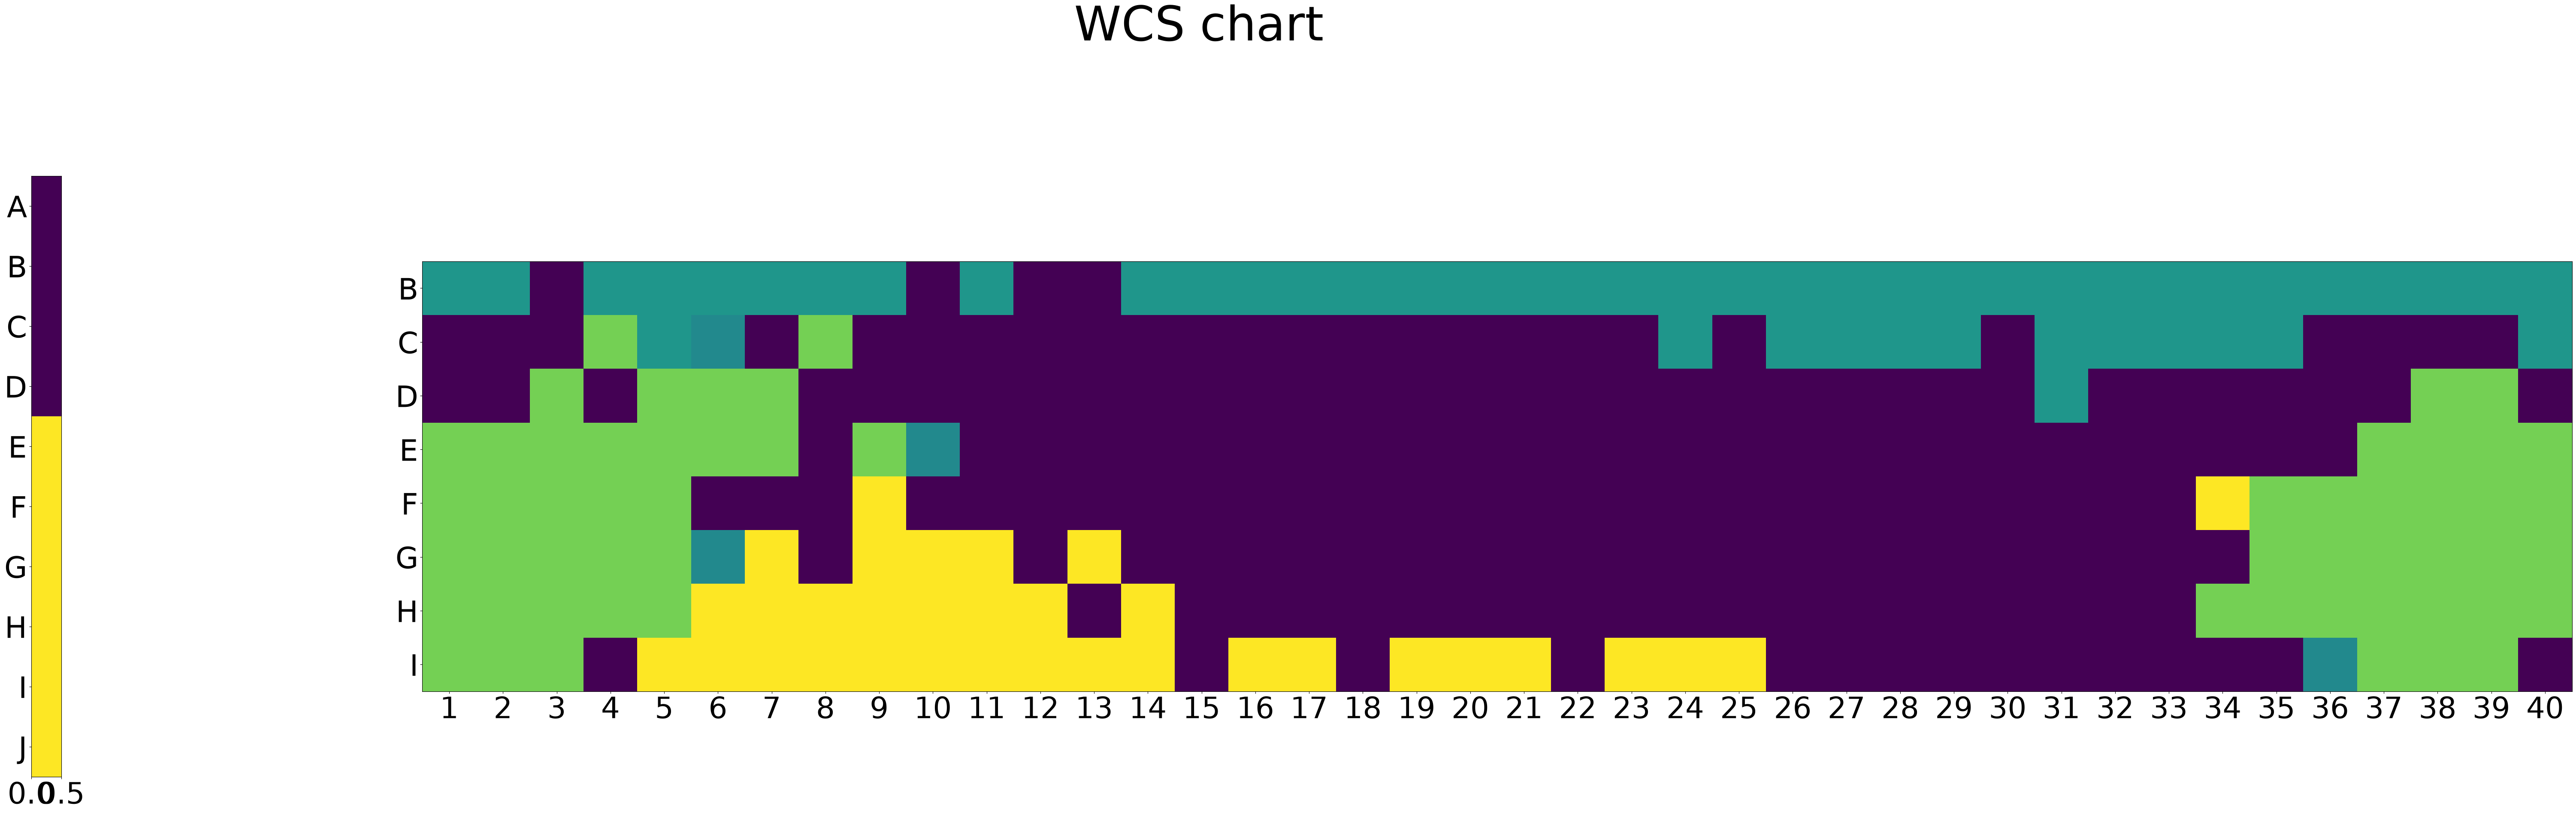

In [23]:
 #Visualizing an Individual speaker's naming data
lg61_spk5 = namingData[61][5]
terms = lg61_spk5.values()
encoded_terms = map_array_to(terms, generate_random_values(terms))
plotValues(encoded_terms)
# **Note**: `plotValues()` is a generic function for visualizing various kinds of information on the chart, suited to needs.



# Operationalizing Colour Complexity
1 - Set size

In [24]:
# count the number of established color terms of the languages, which we define a language complexity
# for each language, keep record of how many times a term gloss appears as a term used by a speaker to name a Munsell chip
color_words_across_all_languages = dict()
total_languages = len(namingData)
language = 1
while language < total_languages + 1:
    speakers = namingData[language]
    color_words_per_language = dict()
    # print(len(speakers))
    for speaker in speakers:
        speaker_terms = set(namingData[language][speaker].values())
        for color in speaker_terms:
            if color not in color_words_per_language:
                color_words_per_language[color] = 1
            else:
                color_words_per_language[color] += 1
    # print(language_color_words)
    # number of established terms = the terms that majority of the speakers use
    num_establish_terms = 0
    for color_word in color_words_per_language.keys():
        if color_word != '*' and color_words_per_language[color_word] >= 0.5 * len(speakers):
            num_establish_terms += 1
    color_words_across_all_languages[language] = num_establish_terms
    language += 1
print(color_words_across_all_languages)

{1: 7, 2: 6, 3: 10, 4: 9, 5: 7, 6: 8, 7: 14, 8: 7, 9: 7, 10: 7, 11: 7, 12: 5, 13: 7, 14: 4, 15: 8, 16: 6, 17: 15, 18: 7, 19: 11, 20: 8, 21: 6, 22: 6, 23: 4, 24: 10, 25: 7, 26: 8, 27: 14, 28: 8, 29: 7, 30: 6, 31: 5, 32: 4, 33: 7, 34: 9, 35: 8, 36: 3, 37: 7, 38: 10, 39: 11, 40: 7, 41: 6, 42: 7, 43: 4, 44: 9, 45: 7, 46: 11, 47: 6, 48: 7, 49: 8, 50: 6, 51: 7, 52: 10, 53: 5, 54: 7, 55: 9, 56: 5, 57: 11, 58: 5, 59: 8, 60: 4, 61: 5, 62: 8, 63: 7, 64: 6, 65: 7, 66: 4, 67: 15, 68: 11, 69: 8, 70: 7, 71: 9, 72: 9, 73: 5, 74: 4, 75: 7, 76: 7, 77: 3, 78: 9, 79: 6, 80: 8, 81: 6, 82: 5, 83: 8, 84: 11, 85: 7, 86: 12, 87: 6, 88: 8, 89: 7, 90: 7, 91: 12, 92: 9, 93: 7, 94: 6, 95: 8, 96: 6, 97: 5, 98: 9, 99: 6, 100: 6, 101: 8, 102: 5, 103: 7, 104: 3, 105: 3, 106: 12, 107: 5, 108: 6, 109: 6, 110: 8}


2 - Entropy

In [25]:
import math
# accounting for frequency, we will define the language complexity as entropy as used in information theory

color_words_per_language = dict()
languages_complexities = dict()
total_languages = len(namingData)
l = 1
while l < total_languages + 1:
    language_color_words = dict()
    for i in namingData[l]:
        for chip, color in namingData[l][i].items():
            if color not in language_color_words:
                language_color_words[color] = 1
            else:
                language_color_words[color] += 1
        color_words_per_language[l] = language_color_words
    # print(language_color_words)
    if '*' in language_color_words:
        language_color_words.pop('*')
    t = sum(language_color_words.values())
    # print(t)
    for k,v in language_color_words.items():
        language_color_words[k] = v/t

    entropy_for_each_language = -sum(v*math.log(v,2) for v in language_color_words.values())
    # print(entropy_for_each_language)
    languages_complexities[l] = entropy_for_each_language
    l += 1
print(languages_complexities.keys())



dict_keys([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110])


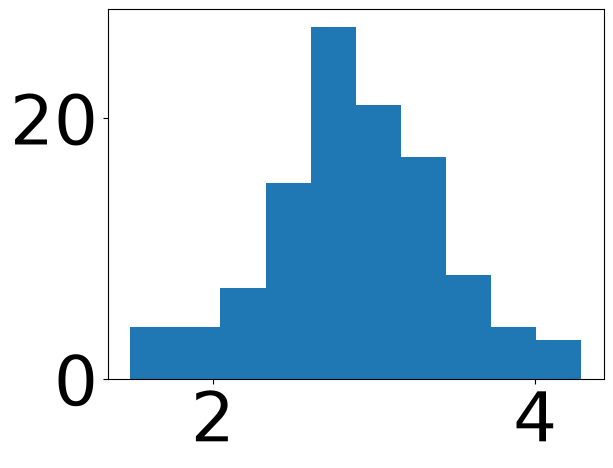

In [26]:
plt.hist(languages_complexities.values())
plt.show()

## Experiment 1 - Between Speaker Agreement in Colour Naming

In [27]:
# now we want to examine color naming consistency across the 330 Munsell chips for
# so we will check what does each speaker in each language name a chip as.

total_chips = 330 # assumes all speakers in every language is asked to name all 330 Munsell chips
color_naming_consistency_across_languages = dict()
# across the 110 languages
for language in range(1, total_languages + 1):
    # across the speakers in the language
    speakers = namingData[language]
    # keep track of color naming of all the 330 Munsell chips by the speakers in the language
    color_naming_all_chips = dict()
    # across the 330 chips
    for chip in range(1, total_chips + 1):
        # store the color naming for each chip
        chip_naming = []
        color_naming_per_chip = dict()
        for speaker in range(1, len(speakers) + 1):
            chip_naming.append(namingData[language][speaker][chip])
        # print(chip_naming)

        # store the proportion of the speakers name each chip with a color word
        for color in chip_naming:
            if color not in color_naming_per_chip:
                color_naming_per_chip[color] = 1/len(speakers)
            else:
                color_naming_per_chip[color] += 1/len(speakers)
        # print(color_naming_per_chip)
        color_naming_all_chips['chip ' + str(chip)] = color_naming_per_chip
    # print(color_naming_all_chips)

    # quantify the consistency in color naming for each language
    language_consistency = sum(max(chip.values()) for chip in color_naming_all_chips.values())/len(color_naming_all_chips)
    # print(language_consistency)
    color_naming_consistency_across_languages[language] = language_consistency
print(color_naming_consistency_across_languages)

{1: 0.5500606060606061, 2: 0.529924242424242, 3: 0.4627878787878784, 4: 0.6144588744588741, 5: 0.7388888888888889, 6: 0.5233445566778893, 7: 0.6710303030303026, 8: 0.6113939393939395, 9: 0.6687878787878797, 10: 0.5869090909090909, 11: 0.6501818181818174, 12: 0.786060606060606, 13: 0.6163636363636367, 14: 0.7521212121212119, 15: 0.6669090909090912, 16: 0.6790303030303028, 17: 0.6182828282828283, 18: 0.4575757575757576, 19: 0.6943030303030301, 20: 0.72617079889807, 21: 0.7633939393939392, 22: 0.6621818181818174, 23: 0.7098181818181812, 24: 0.7271515151515154, 25: 0.8761212121212123, 26: 0.6912727272727273, 27: 0.5655757575757573, 28: 0.6373333333333329, 29: 0.7870303030303027, 30: 0.7318787878787877, 31: 0.863272727272727, 32: 0.6553939393939391, 33: 0.8545454545454547, 34: 0.6037575757575763, 35: 0.6957575757575757, 36: 0.8689696969696972, 37: 0.6973333333333331, 38: 0.5948051948051946, 39: 0.5472727272727275, 40: 0.6914702581369231, 41: 0.7933333333333339, 42: 0.5944242424242424, 43: 0

Results for Set Complexity Measure

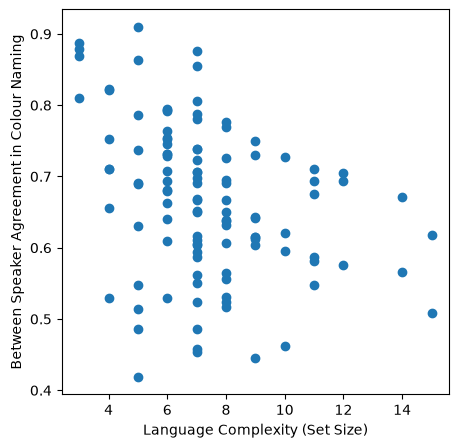

R Correlation: -0.3463364535201128
P-Value: 0.00021030703649371524


In [28]:
import scipy

# now we have to examine the correlation between the language complexity, define as the number of established color terms, and the color naming consistency.
x1 = [] # language complexity
y = [] # color naming consistency

for _, num in color_words_across_all_languages.items():
    x1.append(num)

for _, val in color_naming_consistency_across_languages.items():
    y.append(val)
# plotting language complexity against color naming consistency
plt.figure(figsize=(5, 5))
plt.scatter(x1, y)
plt.tick_params(axis="both", labelsize=10)
plt.xlabel("Language Complexity (Set Size)")
plt.ylabel("Between Speaker Agreement in Colour Naming")

plt.show()

# the correlation coefficient:
corr_1 = scipy.stats.pearsonr(x1, y)
print("R Correlation:", corr_1.statistic)
print("P-Value:", corr_1[1])

Results for Entropy Complexity Measure

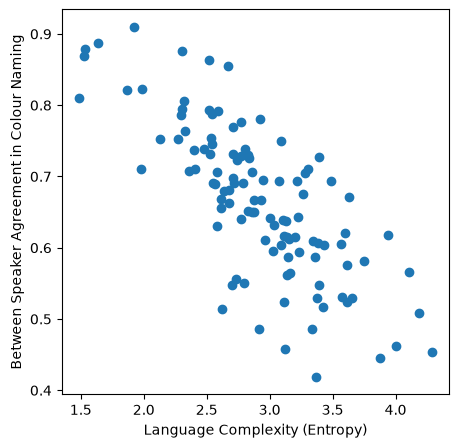

R Correlation: -0.7547267281962925
P-Value: 1.7057808904884557e-21


In [29]:
x2 = []
for _, num in languages_complexities.items():
    x2.append(num)

# plotting language complexity against color naming consistency
plt.figure(figsize=(5, 5))
plt.scatter(x2, y)
plt.tick_params(axis="both", labelsize=10)
plt.xlabel("Language Complexity (Entropy)")
plt.ylabel("Between Speaker Agreement in Colour Naming")


plt.show()

# the correlation coefficient:
corr_2 = scipy.stats.pearsonr(x2, y)
print("R Correlation:", corr_2.statistic)
print("P-Value:", corr_2[1])




## Experiment 2  - Between Speaker Agreement in Foci Identificaiton

In [30]:
def create_coordinates(s):
    key = str(s).replace(":", "").strip()
    index = coordIndex[key]
    return tuple(float(x) for x in cielabCoord[index])

foci_by_language = {} #chip_foci_identified_per_chip_by_language

for lang_key in fociData:
    foci_by_term = {}
    # term: [list of coords mentioned]
    for speaker in fociData[lang_key]:
        foci = fociData[lang_key][speaker]
        for term in foci:
            if len(foci[term]) > 1:
                c = []
                # convert all of its foci to coordinates
                for chip in foci[term]:
                    c.append(create_coordinates(chip))
                # find the center
                arr = np.array(c)
                f = tuple(arr.mean(axis=0))
            else:
                f = create_coordinates(foci[term][0])
            if term in foci_by_term.keys():
                foci_by_term[term].append(f)
            else:
                foci_by_term[term] = [f]

    foci_by_language[lang_key] = foci_by_term

#foci_by_language is a dictionary of [language] --> [colour terms] --> [chip coordinates]

In [31]:
df = pd.DataFrame(
    [
        {
            "language": language,
            "term": term,
            "chip": chip,
        }
        for language, terms in foci_by_language.items()
        for term, chips in terms.items()
        for chip in chips
    ],
    columns=["language", "term", "chip"],
)

print(df)

       language term                                  chip
0             1   LF                   (96.0, -0.06, 0.06)
1             1   LF                   (96.0, -0.06, 0.06)
2             1   LF                   (96.0, -0.06, 0.06)
3             1   LF                   (96.0, -0.06, 0.06)
4             1   LF                   (96.0, -0.06, 0.06)
...         ...  ...                                   ...
17887       110   CH                 (20.54, 10.16, 21.44)
17888       110   CH               (30.77, 16.035, 32.035)
17889       110    M  (51.57, 24.725, -35.370000000000005)
17890       110   RI                 (20.54, 13.28, 18.21)
17891       110    S    (46.394999999999996, -0.03, 0.035)

[17892 rows x 3 columns]


In [32]:
# For each lang
# for each term
# filter out terms with  less than 2 (?) foci identified
    # find center /column mean
    # take Euclidean distance from each foci to mean, square and sum, divide by length of foci list
lang_agreement = {}
for lang in foci_by_language:
    term_agreement = []
    for term in foci_by_language[lang]:
        if len(foci_by_language[lang][term]) >= 2:
            arr = np.array(foci_by_language[lang][term])
            center = arr.mean(axis=0)
            distance = []
            for coord in foci_by_language[lang][term]:
                d = spatial.distance.euclidean(center, coord)
                distance.append(d)
            distance = np.array(np.square(distance))
            term_agreement.append(distance.mean())
    lang_agreement[lang] = np.array(term_agreement).mean()

#Follow up: control for # of categories and check if uncertainty is about the same per each - so languages with equal complexity  should show equally


Results for Set Complexity Measure

R Correlation: -0.10839948334701302
P-Value: 0.2596405005090349


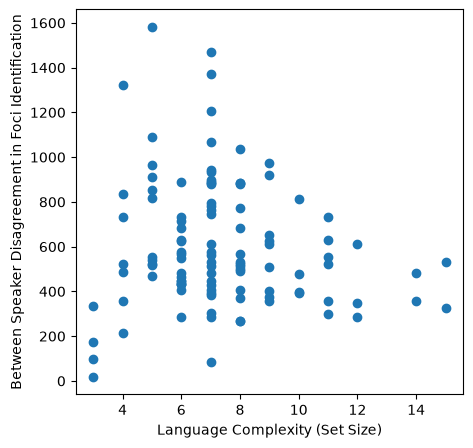

In [33]:
langs = sorted(lang_agreement)   # or any fixed order
x_1 = [color_words_across_all_languages[l] for l in langs]
x_2 = [languages_complexities[l] for l in langs]

y = [lang_agreement[l] for l in langs]

plt.figure(figsize=(5,5))
plt.scatter(x_1, y)
plt.tick_params(axis="both", labelsize=10)
plt.xlabel("Language Complexity (Set Size)")
plt.ylabel("Between Speaker Disagreement in Foci Identification")


corr1 = scipy.stats.pearsonr(x_1, y)
print("R Correlation:", corr1.statistic)
print("P-Value:", corr1[1])


Results for Entropy Complexity Measure

R Correlation: 0.21493521676609634
P-Value: 0.02413766376002211


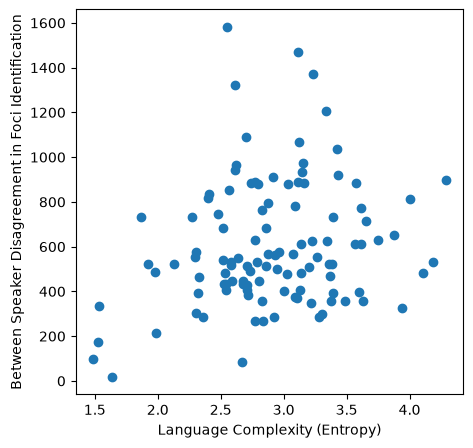

In [34]:
plt.figure(figsize=(5,5))
plt.scatter(x_2, y)
plt.tick_params(axis="both", labelsize=10)
plt.xlabel("Language Complexity (Entropy)")
plt.ylabel("Between Speaker Disagreement in Foci Identification")

corr2 = scipy.stats.pearsonr(x_2, y)

print("R Correlation:", corr2.statistic)
print("P-Value:", corr2[1])

Follow up: control for # of categories and check if uncertainty is about the same per each - so languages with equal complexity  should show equally